# 1. Black–Scholes: can a network learn the delta hedge?

We sell a European call and hedge it by trading the stock at 30 dates. In the Black–Scholes model without transaction costs the answer is known: hold $\Delta_t = \partial C/\partial s$ shares. This part checks that the deep hedging method recovers it, before we use it in settings where no formula exists.

**Setting.** $s_0 = 1$, strike $K = 1$, maturity $T = 3$ months, volatility $\sigma = 35\%$, zero interest rate, $N = 30$ trading dates $t_j = jT/N$.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import blackscholes as bs, simulate
from deephedge.benchmarks import delta_holdings
from deephedge.losses import hedging_loss
from deephedge.models import StateHedge
from deephedge.plotting import COLORS, MUTED, style, save
from deephedge.train import fit

N, T, sigma, K = 30, 0.25, 0.35, 1.0

## Data

Exact simulation on the grid, $S_{t_{j+1}} = S_{t_j} \exp\big(-\tfrac12 \sigma^2 h + \sigma \sqrt{h}\, Z_j\big)$ with $h = T/N$: 100,000 training paths and 10,000 independent test paths.

In [2]:
S_train = simulate.gbm_paths(100_000, seed=0).float()
S_test = simulate.gbm_paths(10_000, seed=1).float()

for name, S in [("train", S_train), ("test", S_test)]:
    S_T = S[:, -1].double()
    print(f"{name}: mean S_T = {S_T.mean():.4f} (s.e. {S_T.std() / len(S_T)**0.5:.4f}, theory 1), "
          f"std log S_T = {S_T.log().std():.4f} (theory {sigma * T**0.5:.4f})")

train: mean S_T = 1.0004 (s.e. 0.0006, theory 1), std log S_T = 0.1753 (theory 0.1750)
test: mean S_T = 0.9993 (s.e. 0.0018, theory 1), std log S_T = 0.1751 (theory 0.1750)


## Model and training

The hedge is a sequence of 30 networks. Network $j$ maps the price $S_{t_j}$ to the number of shares $H_j$ held on $[t_j, t_{j+1})$, so no decision can use a future price. Each network has two hidden layers of 32 ReLU units, and its input is standardised with the mean and standard deviation of the training prices at $t_j$.

The seller receives the Black–Scholes premium $p = C(0, s_0)$, and all networks are trained jointly to minimise the mean squared P&L

$$
\mathbb{E}\Big[\Big(p + \sum_{j=0}^{N-1} H_j\,(S_{t_{j+1}} - S_{t_j}) - (S_T - K)^+\Big)^2\Big].
$$

Adam, batches of 1,000 paths, 40 epochs, learning rate $10^{-3}$ divided by 10 at epochs 25 and 35.

In [3]:
p = bs.price(1.0, K, T, sigma).item()
print(f"premium p = C(0, s0) = {p:.6f}")


def pnl(model, S):
    return p - hedging_loss(model(S[:, :-1, None]), S)[0]


def train(seed, standardise=True):
    torch.manual_seed(seed)
    model = StateHedge(S_train[:, :-1, None])
    if not standardise:
        model.loc.zero_()
        model.scale.fill_(1.0)
    return fit(model, (S_train,), lambda m, s: pnl(m, s).pow(2).mean(),
               n_epochs=40, milestones=(25, 35), progress=False)


model, history = train(seed=0)
print(f"training loss after 40 epochs: {history[-1]:.3e}")

premium p = C(0, s0) = 0.069726


training loss after 40 epochs: 1.178e-04


## Deep hedge vs delta hedge

The analytical hedge is $H^{\text{BS}}_t(s) = \Phi(d_+)$ with $d_+ = \dfrac{\log(s/K) + \sigma^2 (T-t)/2}{\sigma\sqrt{T-t}}$. Both hedges are evaluated on the same 10,000 test paths.

                     mean        std
deep hedge       0.000014   0.010920
delta hedge      0.000012   0.010895
no hedge         0.000364   0.113420

std ratio, deep / delta:       1.0023
path-by-path correlation:      0.9974


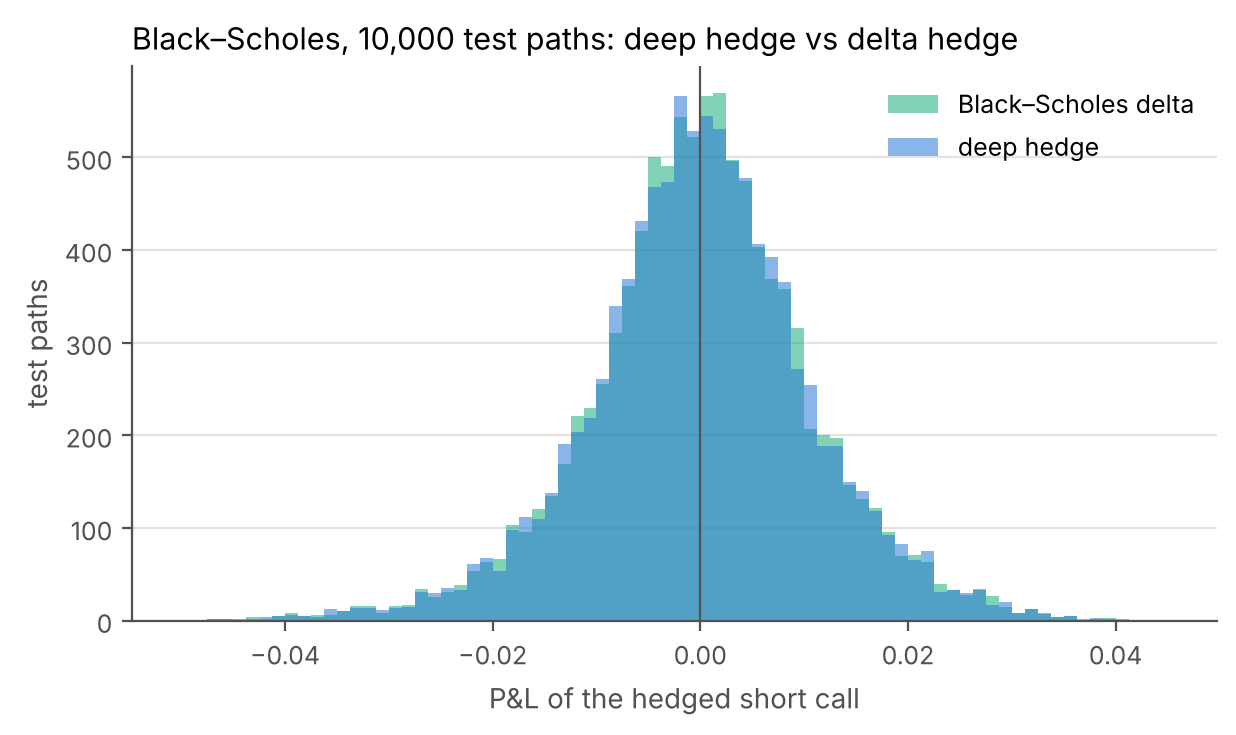

In [4]:
with torch.no_grad():
    pnl_deep = pnl(model, S_test)
S64 = S_test.double()
pnl_delta = (p - hedging_loss(delta_holdings(S64, sigma), S64)[0]).float()
pnl_naked = p - torch.relu(S_test[:, -1] - K)

print(f"{'':14s}{'mean':>11s}{'std':>11s}")
for name, x in [("deep hedge", pnl_deep), ("delta hedge", pnl_delta), ("no hedge", pnl_naked)]:
    print(f"{name:14s}{x.mean():11.6f}{x.std():11.6f}")
print(f"\nstd ratio, deep / delta:       {pnl_deep.std() / pnl_delta.std():.4f}")
print(f"path-by-path correlation:      {torch.corrcoef(torch.stack([pnl_deep, pnl_delta]))[0, 1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(-0.05, 0.045, 77)
ax.hist(pnl_delta.numpy(), bins=bins, color=COLORS["delta"], alpha=0.55, label="Black–Scholes delta")
ax.hist(pnl_deep.numpy(), bins=bins, color=COLORS["deep"], alpha=0.55, label="deep hedge")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("P&L of the hedged short call")
ax.set_ylabel("test paths")
ax.set_title("Black–Scholes, 10,000 test paths: deep hedge vs delta hedge", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
style(ax)
save(fig, "part1_pnl")
plt.show()

The two hedges are practically the same. Both P&Ls are centred on zero, their standard deviations differ by 0.2%, and their path-by-path correlation is 0.997: the network reproduces the outcome of the delta hedge on almost every path, not only its distribution. Hedging divides the risk of the naked short call by ten. What remains, about 16% of the premium, is the error of rebalancing only 30 times, which both hedges share (last section).

## What the networks learned

Each network $H_j$ is compared with the delta at the same date on a grid of prices. The shaded area is the central 98% of the training prices at $t_j$, the only region where the network receives a training signal.

  j   training prices, 1%-99%   mean |H_j - delta| inside   outside
  0            [1.000, 1.000]                      0.0002    0.3528
 10            [0.786, 1.259]                      0.0039    0.0644
 20            [0.710, 1.380]                      0.0034    0.0100
 29            [0.660, 1.476]                      0.0043    0.0086


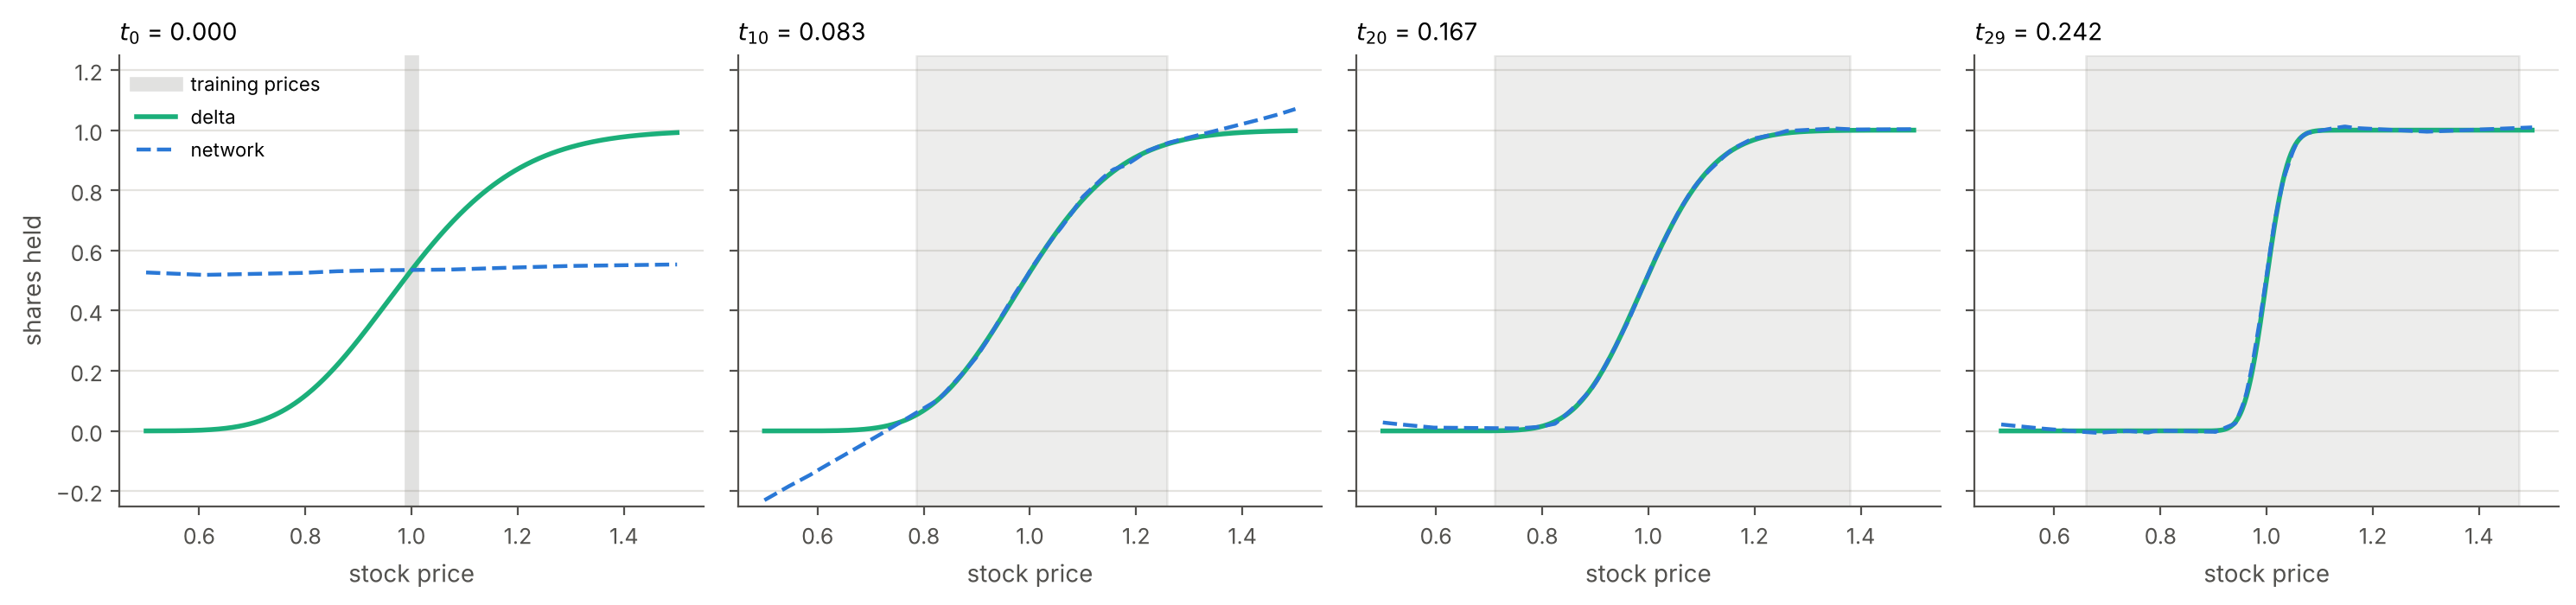

In [5]:
s_grid = torch.linspace(0.5, 1.5, 501)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
print(f"{'j':>3s}{'training prices, 1%-99%':>26s}{'mean |H_j - delta| inside':>28s}{'outside':>10s}")
for ax, j in zip(axes, [0, 10, 20, 29]):
    t_j = j * T / N
    with torch.no_grad():
        H_net = model.decision(j, s_grid[:, None])
    H_bs = bs.delta(s_grid, K, T - t_j, sigma).float()
    lo, hi = torch.quantile(S_train[:, j], torch.tensor([0.01, 0.99])).tolist()
    inside = (s_grid >= lo) & (s_grid <= hi)
    gap = (H_net - H_bs).abs()
    gap_in = gap[inside].mean().item() if inside.any() else gap[250].item()     # j = 0: all paths start at 1
    print(f"{j:3d}{f'[{lo:.3f}, {hi:.3f}]':>26s}{gap_in:28.4f}{gap[~inside].mean().item():10.4f}")

    if j == 0:
        ax.axvline(1.0, color=COLORS["grey"], lw=6, alpha=0.25, label="training prices")
    else:
        ax.axvspan(lo, hi, color=COLORS["grey"], alpha=0.15, label="training prices")
    ax.plot(s_grid, H_bs, color=COLORS["delta"], lw=2, label="delta")
    ax.plot(s_grid, H_net, color=COLORS["deep"], lw=1.6, ls="--", label="network")
    ax.set_ylim(-0.25, 1.25)
    ax.set_title(f"$t_{{{j}}}$ = {t_j:.3f}", loc="left", fontsize=10)
    ax.set_xlabel("stock price")
    style(ax)
axes[0].set_ylabel("shares held")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
save(fig, "part1_policy")
plt.show()

Inside the training range the networks match the delta at every date (mean gap at most 0.004). Outside it they extrapolate. At $t_0$ every path starts at $s_0 = 1$, so $H_0$ only has to learn one number, $\Delta_0(1) \approx 0.535$, and stays flat elsewhere. The agreement improves with time because the price distribution widens like $\sigma\sqrt{t_j}$. The gaps cost nothing: the hedge is never used at prices that do not occur.

## What made training work

The only change to a plain network is the input standardisation. Same seed, architecture and optimiser, with the raw price as input:

test P&L std:  raw input 0.011345 | standardised 0.010920 | delta 0.010895
training loss after 5 epochs:  raw input 3.476e-04 | standardised 1.231e-04


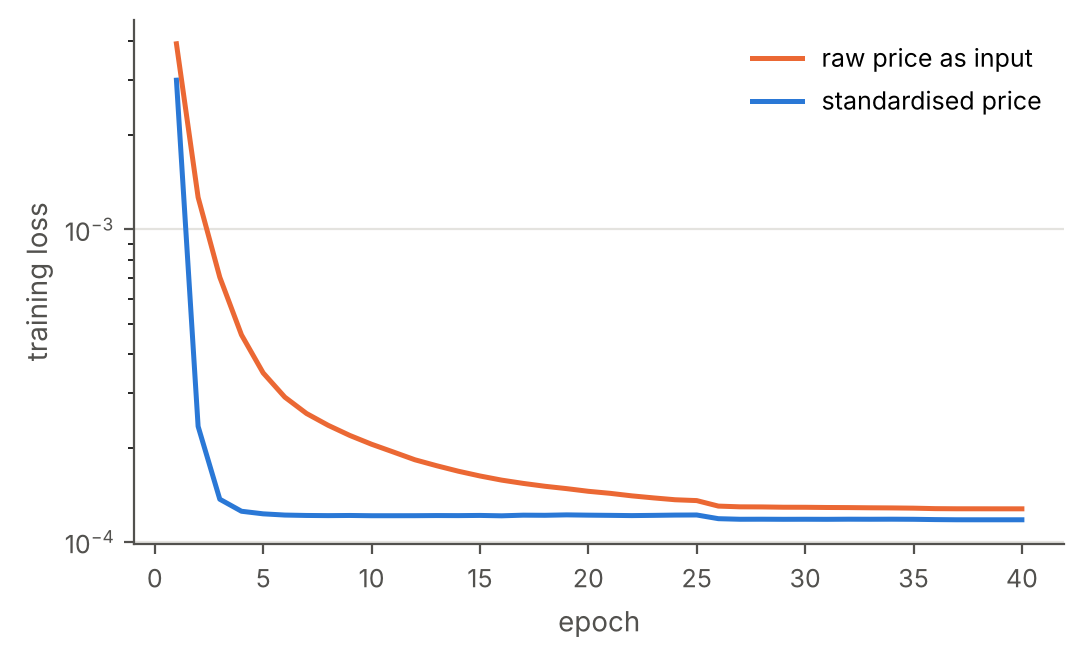

In [6]:
model_raw, history_raw = train(seed=0, standardise=False)
with torch.no_grad():
    std_raw = pnl(model_raw, S_test).std().item()
print(f"test P&L std:  raw input {std_raw:.6f} | standardised {pnl_deep.std():.6f} | delta {pnl_delta.std():.6f}")
print(f"training loss after 5 epochs:  raw input {history_raw[4]:.3e} | standardised {history[4]:.3e}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogy(range(1, 41), history_raw, color=COLORS["band"], lw=1.8, label="raw price as input")
ax.semilogy(range(1, 41), history, color=COLORS["deep"], lw=1.8, label="standardised price")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss")
ax.legend(frameon=False, fontsize=9)
style(ax)
plt.show()

At early dates the price barely moves away from 1 (its standard deviation at $t_1$ is $\sigma\sqrt{T/N} \approx 0.03$), so a network fed the raw price sees an almost constant input and learns the slope slowly. With the raw input the loss after 5 epochs is three times higher, and after 40 epochs the test standard deviation is still 4% above the delta's, against 0.2% with standardisation.

## Robustness

Two sources of randomness: the test sample (the same model on 50 independent test sets of 10,000 paths) and the training run (four more seeds, which change the initial weights and the order of the mini-batches).

In [7]:
ratios = []
for i in range(50):
    S_new = simulate.gbm_paths(10_000, seed=1000 + i).float()
    S_new64 = S_new.double()
    with torch.no_grad():
        std_deep = pnl(model, S_new).std()
    std_delta = (p - hedging_loss(delta_holdings(S_new64, sigma), S_new64)[0]).std()
    ratios.append((std_deep / std_delta).item())
print(f"50 test sets: std ratio deep / delta between {min(ratios):.5f} and {max(ratios):.5f}, mean {np.mean(ratios):.5f}")

for seed in [1, 2, 3, 4]:
    m, _ = train(seed)
    with torch.no_grad():
        print(f"seed {seed}: std ratio deep / delta = {pnl(m, S_test).std() / pnl_delta.std():.4f}")

50 test sets: std ratio deep / delta between 1.00010 and 1.00386, mean 1.00221


seed 1: std ratio deep / delta = 1.0018


seed 2: std ratio deep / delta = 1.0023


seed 3: std ratio deep / delta = 1.0022


seed 4: std ratio deep / delta = 1.0023


The ratio stays between 1.0001 and 1.0039 across test sets and between 1.0018 and 1.0023 across seeds: the match with the delta hedge does not depend on the sample or on the initialisation.

## The limit of this setting: discrete rebalancing

The residual risk above is not a network error: the delta hedge replicates the call only in continuous time. With $N$ rebalancing dates:

In [8]:
print(f"{'N':>5s}{'std of delta P&L':>18s}{'std / premium':>15s}{'std x sqrt(N)':>15s}")
for n in [5, 10, 30, 90, 270]:
    S_n = simulate.gbm_paths(100_000, seed=100 + n, n_steps=n)
    x = p - hedging_loss(delta_holdings(S_n, sigma), S_n)[0]
    print(f"{n:5d}{x.std():18.5f}{x.std() / p:15.1%}{x.std() * n**0.5:15.4f}")

    N  std of delta P&L  std / premium  std x sqrt(N)
    5           0.02568          36.8%         0.0574
   10           0.01853          26.6%         0.0586


   30           0.01092          15.7%         0.0598


   90           0.00640           9.2%         0.0607


  270           0.00371           5.3%         0.0610


The error falls like $1/\sqrt{N}$ (the last column is nearly constant): dividing it by three takes nine times as many trades. Without frictions trading is free, so this is harmless. With transaction costs every trade has a price, the delta hedge is no longer the right answer, and deciding *when* to trade becomes the problem. That is part 3. Part 2 first leaves the complete market.